In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load working sample
df = pd.read_csv("../data/processed/craigslist_30k_sample.csv")

# 2. Filter Target Outliers
df_clean = df[(df['price'] >= 500) & (df['price'] <= 100000)].copy()
print(f"Rows remaining after price filtering: {len(df_clean)} (dropped {len(df) - len(df_clean)} rows)")

# 3. Feature Engineering
dataset_year = 2021
df_clean['vehicle_age'] = dataset_year - df_clean['year']
df_clean['miles_per_year'] = df_clean['odometer'] / (df_clean['vehicle_age'].clip(lower=0) + 1)

# 4. Define Feature Sets
num_features = ['odometer', 'vehicle_age', 'miles_per_year']
cat_features = ['manufacturer', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'state']

X = df_clean[num_features + cat_features]
y = df_clean['price']

# 5. Train/Test Split (80% Train, 20% Protected Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Build Leakage-Free Preprocessing Pipelines
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

# 7. Define Baseline Models
dummy_model = Pipeline([
    ('prep', preprocessor),
    ('regressor', DummyRegressor(strategy='median'))
])

ridge_model = Pipeline([
    ('prep', preprocessor),
    ('regressor', RidgeCV(alphas=np.logspace(-2, 3, 10)))
])

# 8. 5-Fold Cross-Validation Evaluation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

dummy_cv = cross_validate(dummy_model, X_train, y_train, cv=cv, scoring=scoring)
ridge_cv = cross_validate(ridge_model, X_train, y_train, cv=cv, scoring=scoring)

print("\n--- 5-Fold Cross-Validation Results (Training Set) ---")
print(f"Dummy Baseline RMSE: ${-dummy_cv['test_rmse'].mean():,.2f} (± ${dummy_cv['test_rmse'].std():,.2f})")
print(f"Ridge Baseline RMSE: ${-ridge_cv['test_rmse'].mean():,.2f} (± ${ridge_cv['test_rmse'].std():,.2f})")
print(f"Ridge Baseline R2:   {ridge_cv['test_r2'].mean():.4f}")

# 9. Final Test Set Evaluation
ridge_model.fit(X_train, y_train)
y_pred = ridge_model.predict(X_test)

print("\n--- Final Protected Test Set Evaluation (Ridge Baseline) ---")
print(f"Test MAE:  ${mean_absolute_error(y_test, y_pred):,.2f}")
print(f"Test RMSE: ${np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}")
print(f"Test R2:   {r2_score(y_test, y_pred):.4f}")

Rows remaining after price filtering: 26974 (dropped 3026 rows)



--- 5-Fold Cross-Validation Results (Training Set) ---
Dummy Baseline RMSE: $14,789.17 (± $422.55)
Ridge Baseline RMSE: $10,958.68 (± $388.21)
Ridge Baseline R2:   0.4206



--- Final Protected Test Set Evaluation (Ridge Baseline) ---
Test MAE:  $7,655.73
Test RMSE: $10,853.60
Test R2:   0.4333


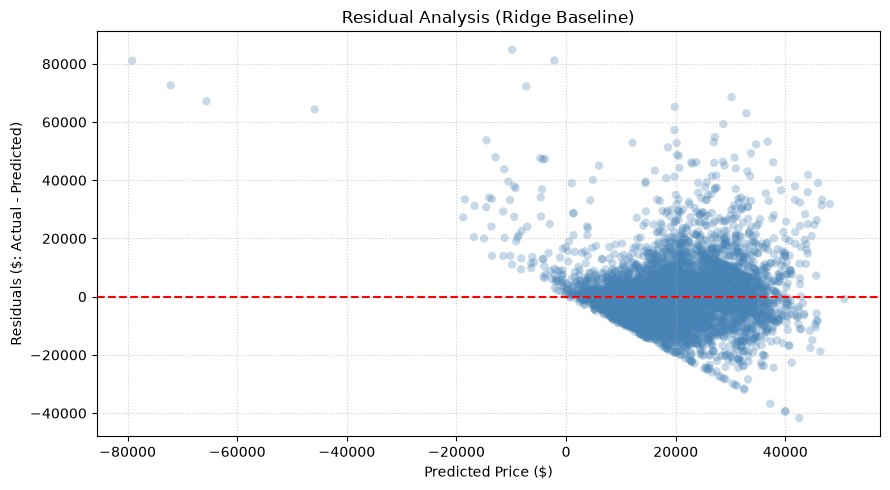

In [2]:
import matplotlib.pyplot as plt

# Residual Analysis
residuals = y_test - y_pred

plt.figure(figsize=(9, 5))
plt.scatter(y_pred, residuals, alpha=0.3, color='steelblue', edgecolor='none')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel("Predicted Price ($)")
plt.ylabel("Residuals ($: Actual - Predicted)")
plt.title("Residual Analysis (Ridge Baseline)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [3]:
# Extract feature names from fitted ColumnTransformer
feature_names = ridge_model.named_steps['prep'].get_feature_names_out()

# Get fitted Ridge coefficients
coefficients = ridge_model.named_steps['regressor'].coef_

# Create DataFrame of top features
coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Abs_Coef', ascending=False).drop(columns='Abs_Coef')

print("--- Top 15 Most Influential Features ---")
print(coef_df.head(15).to_string(index=False))

--- Top 15 Most Influential Features ---
                       Feature   Coefficient
     cat__manufacturer_ferrari  69059.150754
cat__manufacturer_aston-martin -30334.778778
       cat__manufacturer_tesla  14728.247462
      cat__manufacturer_datsun  14178.916991
     cat__manufacturer_porsche  10155.603215
              cat__fuel_diesel   9351.984784
  cat__manufacturer_land rover  -9151.145448
      cat__manufacturer_saturn  -8336.813339
        cat__manufacturer_fiat  -8222.165857
  cat__manufacturer_mitsubishi  -7522.757817
       cat__manufacturer_rover   7459.059720
     cat__title_status_missing   6932.035784
                 cat__type_bus  -6478.009643
       cat__manufacturer_mazda  -6319.101084
         cat__manufacturer_kia  -6168.895244
